# Credit Card Default Prediction

**Objective:** Predict `default payment next month` (0 = no default, 1 = default), using historical UCI credit-card data.  
**Data:** [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), Taiwan, 2005.  
**Sampling:** **750 actual class-0 records + 750 actual class-1 records**.  
**Models:** Logistic Regression baseline and RBF-SVM.


## 0 — Install requirements

In [54]:
%pip -q install ucimlrepo numpy pandas matplotlib scikit-learn

## 1 — Download, rename columns, and make an exactly balanced sample

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
N_PER_CLASS = 750

uci = fetch_ucirepo(id=350)
X_full = uci.data.features.copy()
y_full = uci.data.targets.iloc[:, 0].astype(int).copy()

column_mapping = {
    "X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION",
    "X4": "MARRIAGE", "X5": "AGE",
    "X6": "PAY_0", "X7": "PAY_2", "X8": "PAY_3",
    "X9": "PAY_4", "X10": "PAY_5", "X11": "PAY_6",
    "X12": "BILL_AMT1", "X13": "BILL_AMT2", "X14": "BILL_AMT3",
    "X15": "BILL_AMT4", "X16": "BILL_AMT5", "X17": "BILL_AMT6",
    "X18": "PAY_AMT1", "X19": "PAY_AMT2", "X20": "PAY_AMT3",
    "X21": "PAY_AMT4", "X22": "PAY_AMT5", "X23": "PAY_AMT6"
}
X_full = X_full.rename(columns=column_mapping)

feature_cols = list(column_mapping.values())  # All 23 original predictors
missing_cols = sorted(set(feature_cols) - set(X_full.columns))
assert not missing_cols, f"Missing columns: {missing_cols}; found: {X_full.columns.tolist()}"
assert set(y_full.unique()) == {0, 1}, "Unexpected target labels"

# Class-balanced *sampling* from real records, not oversampling or resampling with replacement
class_0_idx = y_full[y_full == 0].sample(n=N_PER_CLASS, random_state=RANDOM_STATE).index
class_1_idx = y_full[y_full == 1].sample(n=N_PER_CLASS, random_state=RANDOM_STATE).index
sampled_idx = np.concatenate([class_0_idx.to_numpy(), class_1_idx.to_numpy()])
np.random.default_rng(RANDOM_STATE).shuffle(sampled_idx)

X = X_full.loc[sampled_idx, feature_cols].reset_index(drop=True)
y = y_full.loc[sampled_idx].reset_index(drop=True)

assert X.shape == (1500, 23)
assert y.value_counts().to_dict() == {0: 750, 1: 750}
print("Original dataset:", len(X_full))
print("Selected dataset:", X.shape)
print("Original class prevalence:", round(y_full.mean(), 3))
print("Balanced class counts:\n", y.value_counts().sort_index())
print("Target: 0 = no default, 1 = default next month")
display(X.head())

Original dataset: 30000
Selected dataset: (1500, 23)
Original class prevalence: 0.221
Balanced class counts:
 Y
0    750
1    750
Name: count, dtype: int64
Target: 0 = no default, 1 = default next month


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,500000,2,3,2,53,-2,-2,-2,-2,-2,...,0,0,0,1150,0,0,0,0,1150,0
1,60000,1,2,2,28,0,0,2,2,2,...,41531,42048,41241,44056,2500,3114,1496,0,3500,0
2,150000,2,2,1,30,0,-1,-1,-1,-1,...,0,1872,0,113,1231,0,1872,0,113,0
3,290000,1,2,1,36,0,0,0,0,0,...,66183,61332,62445,59213,3500,3000,3000,3000,3000,3000
4,210000,2,2,2,29,1,1,-2,-2,-1,...,-3987,-1987,1697,4347,0,0,2000,4000,3000,5000


## 2 — Explore data and demonstrate missing values

Original missing values in selected features: 0

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,1500.0,158260.00,128716.03,10000.0,50000.00,120000.0,222500.00,700000.0
SEX,1500.0,1.57,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,1500.0,1.86,0.74,1.0,1.00,2.0,2.00,6.0
MARRIAGE,1500.0,1.53,0.53,0.0,1.00,2.0,2.00,3.0
AGE,1500.0,35.93,9.58,21.0,28.00,34.0,42.00,73.0
PAY_0,1500.0,0.21,1.24,-2.0,-0.25,0.0,1.00,8.0
PAY_2,1500.0,0.02,1.29,-2.0,-1.00,0.0,0.00,7.0
PAY_3,1500.0,-0.01,1.31,-2.0,-1.00,0.0,0.00,7.0
PAY_4,1500.0,-0.09,1.31,-2.0,-1.00,0.0,0.00,7.0
PAY_5,1500.0,-0.16,1.26,-2.0,-1.00,0.0,0.00,7.0



Missing values after educational masking:
AGE          93
BILL_AMT1    87
dtype: int64


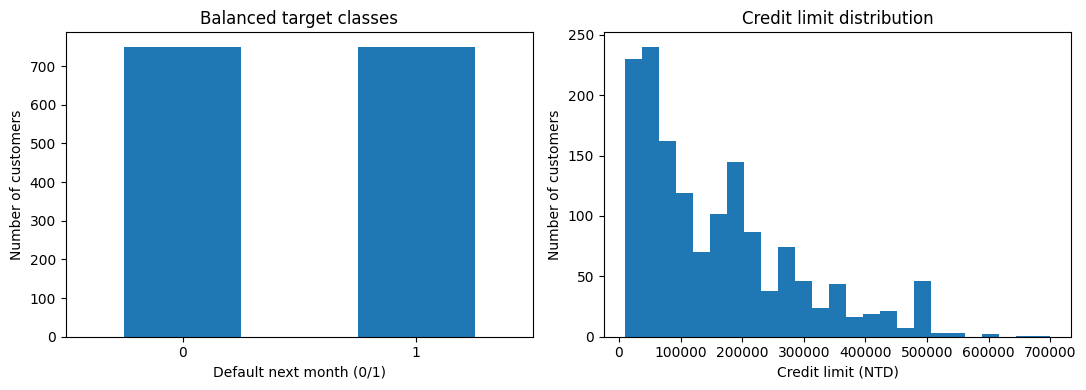

In [56]:
print("Original missing values in selected features:", int(X.isna().sum().sum()))
print("\nSummary statistics:")
display(X.describe().T.round(2))

#Create missing values
rng = np.random.default_rng(RANDOM_STATE)
for col in ["AGE", "BILL_AMT1"]:
    X.loc[rng.random(len(X)) < 0.06, col] = np.nan
print("\nMissing values after educational masking:")
print(X.isna().sum()[X.isna().sum() > 0])

#Plot

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set(title="Balanced target classes", xlabel="Default next month (0/1)", ylabel="Number of customers")
axes[0].tick_params(axis="x", rotation=0)
X["LIMIT_BAL"].plot(kind="hist", bins=25, ax=axes[1])
axes[1].set(title="Credit limit distribution", xlabel="Credit limit (NTD)", ylabel="Number of customers")
plt.tight_layout()
plt.show()

## 3 — Train / test split

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " | Test:", X_test.shape)
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts:", y_test.value_counts().sort_index().to_dict())

Train: (1125, 23)  | Test: (375, 23)
Training class counts: {0: 562, 1: 563}
Test class counts: {0: 188, 1: 187}


## 4 — Domain-motivated feature engineering

Create two ratios using only the same customer's historical input features.

In [58]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

def add_features(frame):
    frame = frame.copy()
    denom = frame["LIMIT_BAL"].clip(lower=1)
    frame["payment_to_limit"] = frame["PAY_AMT1"] / denom
    frame["bill_to_limit"] = frame["BILL_AMT1"].abs() / denom
    return frame

feature_engineering = FunctionTransformer(add_features, validate=False)
print("Columns before:", X_train.shape[1])
print("Columns after engineering:", add_features(X_train).shape[1])

Columns before: 23
Columns after engineering: 25


## 5 — Leakage-safe preprocessing (median + scaling + one-hot encoding)

- Numeric: training-fold **median** imputation → StandardScaler (important for RBF-SVM)
- Categorical: most-frequent imputation → OneHotEncoder (`handle_unknown='ignore'`)
- Treat `SEX`, `EDUCATION`, `MARRIAGE` as categories, not continuous numbers. For this educational exercise, codes are used as categories; in a production system review sensitive attributes and special/unrecognized codes carefully.

In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_features = [
    col for col in feature_cols if col not in categorical_features
] + ["payment_to_limit", "bill_to_limit"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 22
Categorical features: 3


## 6 — Train a baseline Logistic Regression and an RBF-SVM

In [60]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

baseline = Pipeline([
    ("features", clone(feature_engineering)),
    ("prep", clone(preprocess)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
svm = Pipeline([
    ("features", clone(feature_engineering)),
    ("prep", clone(preprocess)),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE))
])

baseline_cv = cross_val_score(baseline, X_train, y_train, scoring="average_precision", cv=cv)
svm_cv = cross_val_score(svm, X_train, y_train, scoring="average_precision", cv=cv)
print("Logistic Regression CV AP:", round(baseline_cv.mean(), 3), "+/-", round(baseline_cv.std(), 3))
print("Default SVM CV AP:       ", round(svm_cv.mean(), 3), "+/-", round(svm_cv.std(), 3))

Logistic Regression CV AP: 0.706 +/- 0.032
Default SVM CV AP:        0.744 +/- 0.022


## 7 — GridSearchCV: tune SVM on training folds only

Explore `C` (regularization), `gamma` (RBF locality), and `class_weight` using GridSearchCV.

In [61]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.01],
    "model__class_weight": [None, "balanced"]
}

search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=-1,
    error_score="raise"
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best params:", search.best_params_)
print("Best CV AP:", round(search.best_score_, 3))

Best params: {'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
Best CV AP: 0.752


## 9 — Final model evaluation and charts (held-out test)

Fit the Logistic Regression baseline on all training data. Tuned SVM (`best_model`) is already refitted by grid search


📌 Model: Logistic Regression
🎯 Accuracy: 0.621

📊 Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.59      0.61       188
           1       0.61      0.66      0.63       187

    accuracy                           0.62       375
   macro avg       0.62      0.62      0.62       375
weighted avg       0.62      0.62      0.62       375

🔍 Confusion Matrix:
[[110  78]
 [ 64 123]]

📌 Model: Tuned SVM
🎯 Accuracy: 0.683

📊 Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.72      0.70       188
           1       0.70      0.64      0.67       187

    accuracy                           0.68       375
   macro avg       0.68      0.68      0.68       375
weighted avg       0.68      0.68      0.68       375

🔍 Confusion Matrix:
[[136  52]
 [ 67 120]]

🏆 Model Comparison:
                     Accuracy  Average Precision  ROC-AUC     F1  Brier Score
Model                  

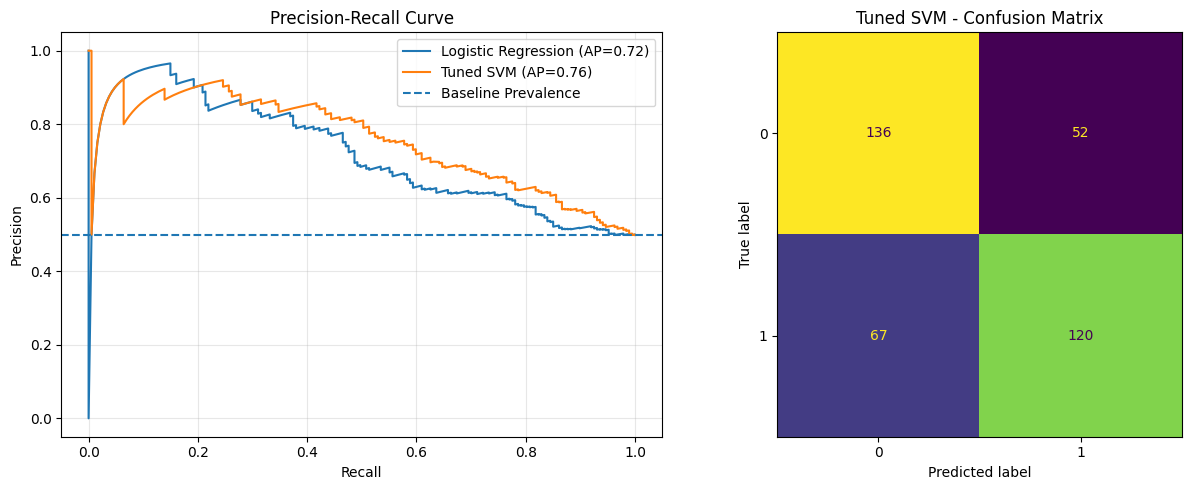


✅ Code 9 completed!


In [62]:

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    f1_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

import pandas as pd
import matplotlib.pyplot as plt

THRESHOLD = 0.5

# Train baseline on the full training set
baseline.fit(X_train, y_train)

# Models to evaluate
models_to_evaluate = {
    "Logistic Regression": baseline,
    "Tuned SVM": best_model
}

results = []
probabilities_dict = {}
predictions_dict = {}

# Evaluate models
for name, model in models_to_evaluate.items():

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= THRESHOLD).astype(int)

    probabilities_dict[name] = probabilities
    predictions_dict[name] = predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Average Precision": average_precision_score(y_test, probabilities),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "Brier Score": brier_score_loss(y_test, probabilities)
    })

    print(f"\n📌 Model: {name}")
    print("🎯 Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("\n📊 Classification Report:")
    print(classification_report(y_test, predictions, zero_division=0))
    print("🔍 Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

# Results comparison
results_df = pd.DataFrame(results).set_index("Model")

print("\n🏆 Model Comparison:")
print(results_df.round(3))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Precision-Recall Curves
for name, probabilities in probabilities_dict.items():

    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(y_test, probabilities)

    axes[0].plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.2f})"
    )

axes[0].axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Baseline Prevalence"
)

axes[0].set_title("Precision-Recall Curve")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Confusion Matrix for Tuned SVM
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_dict["Tuned SVM"],
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Tuned SVM - Confusion Matrix")

plt.tight_layout()
plt.show()

print("\n✅ Code 9 completed!")


## 10 — Permutation importance of original features

📊 Feature Importance:
      Feature  Importance     Std
5       PAY_0      0.1470  0.0244
0   LIMIT_BAL      0.0374  0.0095
21   PAY_AMT5      0.0156  0.0038
11  BILL_AMT1      0.0154  0.0126
6       PAY_2      0.0069  0.0043
14  BILL_AMT4      0.0069  0.0031
7       PAY_3      0.0064  0.0046
3    MARRIAGE      0.0060  0.0028
15  BILL_AMT5      0.0058  0.0021
19   PAY_AMT3      0.0047  0.0040
2   EDUCATION      0.0044  0.0031
16  BILL_AMT6      0.0041  0.0049
12  BILL_AMT2      0.0037  0.0072
8       PAY_4      0.0033  0.0020
22   PAY_AMT6      0.0028  0.0022
1         SEX      0.0020  0.0017
20   PAY_AMT4      0.0016  0.0031
18   PAY_AMT2     -0.0001  0.0029
9       PAY_5     -0.0006  0.0023
17   PAY_AMT1     -0.0009  0.0019
13  BILL_AMT3     -0.0013  0.0025
10      PAY_6     -0.0021  0.0029
4         AGE     -0.0046  0.0032

🏆 Most Important Feature:
PAY_0


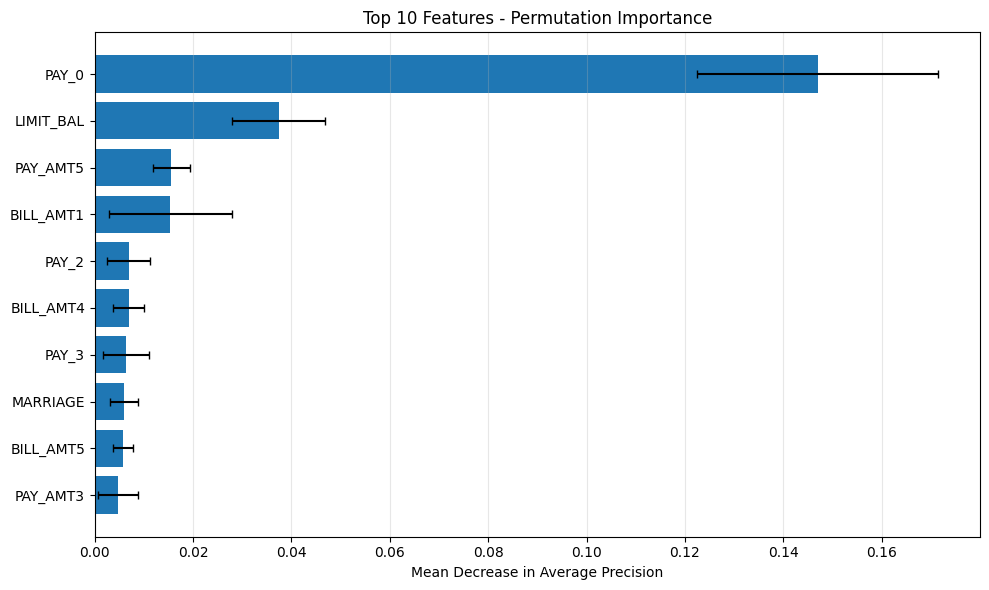


✅ Code 10 completed!


In [63]:

from sklearn.inspection import permutation_importance

import pandas as pd
import matplotlib.pyplot as plt

# Calculate feature importance
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    scoring="average_precision",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

print("📊 Feature Importance:")
print(importance_df.round(4))

print("\n🏆 Most Important Feature:")
print(importance_df.iloc[0]["Feature"])

# Plot top 10 features
top_features = importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"],
    capsize=3
)

plt.xlabel("Mean Decrease in Average Precision")
plt.title("Top 10 Features - Permutation Importance")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✅ Code 10 completed!")


## 11 — Predict one held-out customer's outcome

In [64]:
# Select one customer from the test set
example = X_test.iloc[[0]].copy()

# Predict probability of default
probability = float(
    best_model.predict_proba(example)[0, 1]
)

# Apply fixed threshold
THRESHOLD = 0.5

prediction = int(probability >= THRESHOLD)

# Actual outcome
actual = int(y_test.iloc[0])

print("📋 Customer Information:")
print(example.T)

print("\n🎯 Prediction Results:")
print("Default Probability:", round(probability, 3))
print("Predicted Class:", prediction)
print("Actual Class:", actual)

print(
    "Prediction:",
    "Default" if prediction == 1 else "No Default"
)

print(
    "Result:",
    "Correct ✅" if prediction == actual else "Incorrect ❌"
)

print("\n✅ Code 11 completed!")


📋 Customer Information:
                680
LIMIT_BAL  180000.0
SEX             1.0
EDUCATION       1.0
MARRIAGE        2.0
AGE            28.0
PAY_0           2.0
PAY_2           2.0
PAY_3           2.0
PAY_4           2.0
PAY_5           2.0
PAY_6           2.0
BILL_AMT1  175154.0
BILL_AMT2  175790.0
BILL_AMT3  153515.0
BILL_AMT4  130864.0
BILL_AMT5  131569.0
BILL_AMT6  128983.0
PAY_AMT1     5100.0
PAY_AMT2       50.0
PAY_AMT3    14500.0
PAY_AMT4     4500.0
PAY_AMT5      296.0
PAY_AMT6     4500.0

🎯 Prediction Results:
Default Probability: 0.89
Predicted Class: 1
Actual Class: 0
Prediction: Default
Result: Incorrect ❌

✅ Code 11 completed!


## 12 — Automatic mini report and limitations


In [65]:

# 🚀 Code 12 — Final Project Report

print("=" * 55)
print("📊 CREDIT CARD DEFAULT PREDICTION - FINAL REPORT")
print("=" * 55)

# Dataset information
print("\n📌 Dataset Information")
print("Source: UCI Default of Credit Card Clients")
print("Original Dataset Size:", len(X_full))
print("Sample Size:", len(X))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Original Features:", len(feature_cols))
print("Engineered Features: 2")

# Target distribution
print("\n🎯 Target Distribution")
print(y.value_counts())
print("Sample Default Rate:", round(y.mean() * 100, 2), "%")
print("Original Default Rate:", round(y_full.mean() * 100, 2), "%")

# Model information
print("\n🧠 Model Information")
print("Baseline: Logistic Regression")
print("Main Model: Support Vector Machine (RBF)")
print("Decision Threshold:", THRESHOLD)

# Hyperparameter tuning
print("\n🔧 Best SVM Hyperparameters")
print(search.best_params_)

print(
    "Best Cross-Validation AP:",
    round(search.best_score_, 3)
)

# Model comparison
print("\n📊 Final Model Comparison")
print(results_df.round(3))

# Best model by Average Precision
best_model_name = results_df[
    "Average Precision"
].idxmax()

print("\n🏆 Best Model by Test Average Precision:")
print(best_model_name)

# Feature importance
print("\n🔍 Top 5 Important Features")
print(
    importance_df[
        ["Feature", "Importance"]
    ].head(5).round(4)
)

# Limitations
print("\n⚠️ Project Limitations")
print("- Historical data from Taiwan (2005).")
print("- Balanced sample differs from real default prevalence.")
print("- Small sample size (1,500 records).")
print("- Probabilities may require calibration.")
print("- Feature importance does not imply causation.")

print("\n✅ Project completed successfully!")


📊 CREDIT CARD DEFAULT PREDICTION - FINAL REPORT

📌 Dataset Information
Source: UCI Default of Credit Card Clients
Original Dataset Size: 30000
Sample Size: 1500
Training Records: 1125
Testing Records: 375
Original Features: 23
Engineered Features: 2

🎯 Target Distribution
Y
1    750
0    750
Name: count, dtype: int64
Sample Default Rate: 50.0 %
Original Default Rate: 22.12 %

🧠 Model Information
Baseline: Logistic Regression
Main Model: Support Vector Machine (RBF)
Decision Threshold: 0.5

🔧 Best SVM Hyperparameters
{'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
Best Cross-Validation AP: 0.752

📊 Final Model Comparison
                     Accuracy  Average Precision  ROC-AUC     F1  Brier Score
Model                                                                        
Logistic Regression     0.621              0.718    0.691  0.634        0.227
Tuned SVM               0.683              0.755    0.751  0.669        0.202

🏆 Best Model by Test Average Prec